# Лабораторная работа 1. Диагностика обучения MLP

Ноутбук к заданию `lab1.docx`. Сначала готовлю выборки, потом обучаю MLP
в конфигурациях A-F и собираю метрики.

## 1. Данные и разбиение

Беру `make_moons`: 2400 объектов, шум 0.25, `random_state=2026`.
Сначала отделяю 20% в test, из остатка 25% уходит в validation.
Оба вызова `train_test_split` идут с `random_state=2026` и `stratify`,
поэтому доли классов во всех выборках одинаковые.

In [1]:
from pathlib import Path
import copy
import json

import numpy as np
import torch
import sklearn
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# один поток на CPU, как требует задание
torch.set_num_threads(1)

RANDOM_STATE = 2026
ROOT = Path.cwd()
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

np.set_printoptions(precision=4, suppress=True)
print("torch:", torch.__version__)
print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)
print("устройство: cpu")

torch: 2.15.0+cpu
numpy: 2.5.4
sklearn: 1.9.1
устройство: cpu


In [2]:
X, y = make_moons(n_samples=2400, noise=0.25, random_state=RANDOM_STATE)
print("X:", X.shape, "y:", y.shape)

X_train_all, X_test, y_train_all, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all, test_size=0.25, random_state=RANDOM_STATE,
    stratify=y_train_all,
)
print("train / val / test:", len(X_train), len(X_val), len(X_test))

X: (2400, 2) y: (2400,)
train / val / test: 1440 480 480


In [3]:
# копия до масштабирования нужна для графика
X_train_raw = X_train.copy()

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

In [4]:
sizes = {"train": len(X_train), "val": len(X_val), "test": len(X_test)}
assert sizes == {"train": 1440, "val": 480, "test": 480}, sizes

class_counts = {}
for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    counts = np.bincount(yy, minlength=2)
    class_counts[name] = counts.tolist()
    assert counts.min() > 0, name
    print(f"{name}: 0 -> {counts[0]}, 1 -> {counts[1]}")

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
print("средние train:", mean)
print("std train:", std)
assert np.allclose(mean, 0.0, atol=1e-5)
assert np.allclose(std, 1.0, atol=1e-5)

train: 0 -> 720, 1 -> 720
val: 0 -> 240, 1 -> 240
test: 0 -> 240, 1 -> 240
средние train: [-0.  0.]
std train: [1. 1.]


In [5]:
summary = {
    "sizes": sizes,
    "class_counts": class_counts,
    "train_mean": [float(v) for v in mean],
    "train_std": [float(v) for v in std],
    "scaler_mean": [float(v) for v in scaler.mean_],
    "scaler_scale": [float(v) for v in scaler.scale_],
}
path = RES_DIR / "data_summary.json"
path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("сохранено:", path.relative_to(ROOT))

сохранено: results/data_summary.json


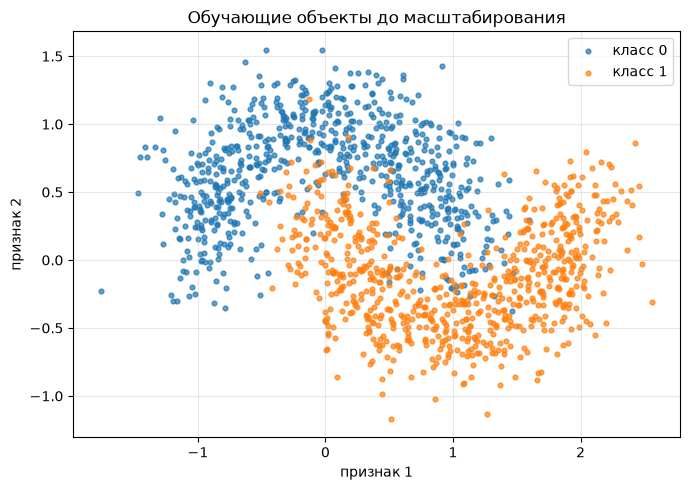

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_train_raw[y_train == 0, 0], X_train_raw[y_train == 0, 1],
           s=12, alpha=0.7, label="класс 0")
ax.scatter(X_train_raw[y_train == 1, 0], X_train_raw[y_train == 1, 1],
           s=12, alpha=0.7, label="класс 1")
ax.set_xlabel("признак 1")
ax.set_ylabel("признак 2")
ax.set_title("Обучающие объекты до масштабирования")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "scatter_train_raw.png", dpi=150)
plt.show()

## Что получилось

Размеры сошлись: 1440 / 480 / 480. В каждой выборке есть оба класса.
После `StandardScaler` средние по train близки к нулю, стандартные
отклонения к единице. Скалер обучен только на train. Если считать
средние и std по всем данным, в обучение попадает информация из
validation и test, а это утечка.

## 2. MLP и цикл обучения

Собираю MLP вручную: L скрытых слоев ширины 32, одна активация на запуск,
линейный выход на 2 логита. Скрытые слои инициализирую Xavier normal
или He normal, выход всегда Xavier, смещения нулевые.

Метрики считаю на полных train и val в режиме eval. Шаг обучения:
zero_grad, forward, loss, backward, step. Для каждого запуска задаю
`torch.manual_seed(seed)` до создания модели и отдельный генератор
для DataLoader с seed `10000 + seed`.

In [7]:
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
import torch.nn.functional as F

X_train_t = torch.from_numpy(X_train)
y_train_t = torch.from_numpy(y_train).long()
X_val_t = torch.from_numpy(X_val)
y_val_t = torch.from_numpy(y_val).long()
X_test_t = torch.from_numpy(X_test)
y_test_t = torch.from_numpy(y_test).long()

print(X_train_t.dtype, y_train_t.dtype)

torch.float32 torch.int64


In [8]:
ACTIVATIONS = {"sigmoid": torch.sigmoid, "tanh": torch.tanh, "relu": F.relu}
WIDTH = 32


class MLP(nn.Module):
    def __init__(self, n_hidden, width, activation, init):
        super().__init__()
        self.activation = ACTIVATIONS[activation]
        sizes = [2] + [width] * n_hidden + [2]
        self.layers = nn.ModuleList()
        for i in range(len(sizes) - 1):
            layer = nn.Linear(sizes[i], sizes[i + 1])
            if i < n_hidden:
                if init == "xavier":
                    nn.init.xavier_normal_(layer.weight, gain=1.0)
                elif init == "he":
                    nn.init.kaiming_normal_(layer.weight, mode="fan_in",
                                            nonlinearity="relu")
                else:
                    raise ValueError(init)
            else:
                nn.init.xavier_normal_(layer.weight, gain=1.0)
            nn.init.zeros_(layer.bias)
            self.layers.append(layer)

    def forward(self, x):
        h = x
        for layer in self.layers[:-1]:
            h = self.activation(layer(h))
        return self.layers[-1](h)


criterion = nn.CrossEntropyLoss(reduction="mean")

In [9]:
def compute_metrics(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        acc = (logits.argmax(dim=1) == y).float().mean().item()
    return loss, acc


def train_model(config, seed, epochs=100, batch_size=128,
                snapshot_epochs=(0, 20, 100)):
    torch.manual_seed(seed)
    model = MLP(config["hidden"], WIDTH, config["activation"], config["init"])
    snapshots = {0: copy.deepcopy(model.state_dict())}

    generator = torch.Generator().manual_seed(10000 + seed)
    loader = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
    )

    if config["optimizer"] == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])
    elif config["optimizer"] == "sgd":
        optimizer = torch.optim.SGD(model.parameters(), lr=config["lr"],
                                    momentum=0.0)
    else:
        raise ValueError(config["optimizer"])

    history = []
    tr_loss, tr_acc = compute_metrics(model, X_train_t, y_train_t)
    va_loss, va_acc = compute_metrics(model, X_val_t, y_val_t)
    history.append({"epoch": 0, "train_loss": tr_loss,
                    "train_accuracy": tr_acc, "val_loss": va_loss,
                    "val_accuracy": va_acc})

    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            if not torch.isfinite(loss):
                raise RuntimeError(f"loss не конечен на эпохе {epoch}")
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc = compute_metrics(model, X_train_t, y_train_t)
        va_loss, va_acc = compute_metrics(model, X_val_t, y_val_t)
        history.append({"epoch": epoch, "train_loss": tr_loss,
                        "train_accuracy": tr_acc, "val_loss": va_loss,
                        "val_accuracy": va_acc})
        if epoch in snapshot_epochs:
            snapshots[epoch] = copy.deepcopy(model.state_dict())

    return model, history, snapshots


CONFIGS = {
    "A": {"hidden": 6, "activation": "sigmoid", "init": "xavier",
          "optimizer": "adam", "lr": 0.003},
    "B": {"hidden": 6, "activation": "tanh", "init": "xavier",
          "optimizer": "adam", "lr": 0.003},
    "C": {"hidden": 6, "activation": "relu", "init": "xavier",
          "optimizer": "adam", "lr": 0.003},
    "D": {"hidden": 6, "activation": "relu", "init": "he",
          "optimizer": "adam", "lr": 0.003},
    "E": {"hidden": 6, "activation": "relu", "init": "he",
          "optimizer": "sgd", "lr": 0.05},
    "F": {"hidden": 1, "activation": "relu", "init": "he",
          "optimizer": "adam", "lr": 0.003},
}

### Самопроверка

Число параметров считаю вручную. Для L = 1: `2*32+32 + 32*2+2 = 162`.
Для L = 6: `2*32+32 + 5*(32*32+32) + 32*2+2 = 5442`.
Дальше сверяю с `sum(p.numel() for p in model.parameters())`.

In [10]:
xb = X_train_t[:8]
yb = y_train_t[:8]
torch.manual_seed(0)

for n_hidden, expected in ((1, 162), (6, 5442)):
    model = MLP(n_hidden, WIDTH, "relu", "he")
    logits = model(xb)
    loss = criterion(logits, yb)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"L={n_hidden}: вход {tuple(xb.shape)}, выход {tuple(logits.shape)}, "
          f"loss {loss.item():.4f}, loss.ndim={loss.ndim}, "
          f"параметров {n_params}")
    assert tuple(logits.shape) == (8, 2)
    assert loss.ndim == 0
    assert n_params == expected, (n_params, expected)

L=1: вход (8, 2), выход (8, 2), loss 0.7912, loss.ndim=0, параметров 162
L=6: вход (8, 2), выход (8, 2), loss 1.6682, loss.ndim=0, параметров 5442


In [11]:
torch.manual_seed(0)
model = MLP(6, WIDTH, "relu", "he")
model.zero_grad()
loss = criterion(model(xb), yb)
loss.backward()

for i, layer in enumerate(model.layers[:-1], start=1):
    grad = layer.weight.grad
    assert grad is not None, f"нет градиента у слоя {i}"
    assert grad.shape == layer.weight.shape, f"форма не совпала у слоя {i}"
    assert torch.isfinite(grad).all(), f"градиент не конечен у слоя {i}"
    print(f"слой {i}: grad {tuple(grad.shape)}, "
          f"норма {grad.norm().item():.4f}")

слой 1: grad (32, 2), норма 0.1766
слой 2: grad (32, 32), норма 0.5406
слой 3: grad (32, 32), норма 0.4276
слой 4: grad (32, 32), норма 0.4330
слой 5: grad (32, 32), норма 0.4464
слой 6: grad (32, 32), норма 0.3465


Проверки сошлись: вход (8, 2), выход (8, 2), loss скаляр. Параметров
162 при L = 1 и 5442 при L = 6. Градиенты всех скрытых слоев есть,
формы совпадают с весами, значения конечные.

### Короткий прогон цикла

Одна эпоха на конфигурации D, чтобы проверить, что обучение идет
и метрики считаются. Полные 100 эпох для A-F будут в разделе 3.

In [12]:
demo_model, demo_history, _ = train_model(CONFIGS["D"], seed=11, epochs=1)
for row in demo_history:
    print(f"эпоха {row['epoch']}: train loss {row['train_loss']:.4f}, "
          f"train acc {row['train_accuracy']:.3f}, "
          f"val loss {row['val_loss']:.4f}, "
          f"val acc {row['val_accuracy']:.3f}")

эпоха 0: train loss 0.5591, train acc 0.778, val loss 0.5655, val acc 0.760
эпоха 1: train loss 0.2936, train acc 0.867, val loss 0.2988, val acc 0.856


## 3. Контролируемые эксперименты

Запускаю 12 обучений: конфигурации A-F, каждая с seed 11 и 29.
Условия одинаковые, различаются только настройки из таблицы.
Метрики пишу в `results/metrics.csv`, модели на эпохах 0, 20 и 100
сохраняю в памяти для следующих разделов.

In [13]:
import csv
import time

RUNS = {}
HISTORY = {}
SNAPSHOTS = {}

start = time.time()
for code in CONFIGS:
    for seed in (11, 29):
        model, history, snaps = train_model(CONFIGS[code], seed)
        RUNS[(code, seed)] = model
        HISTORY[(code, seed)] = history
        SNAPSHOTS[(code, seed)] = snaps
        last = history[-1]
        print(f"{code} seed {seed}: val loss {last['val_loss']:.4f}, "
              f"val acc {last['val_accuracy']:.3f}")
print(f"готово, {time.time() - start:.1f} с")

A seed 11: val loss 0.1863, val acc 0.919


A seed 29: val loss 0.1787, val acc 0.919


B seed 11: val loss 0.1874, val acc 0.913


B seed 29: val loss 0.1714, val acc 0.921


C seed 11: val loss 0.2038, val acc 0.925


C seed 29: val loss 0.2088, val acc 0.908


... (2 outputs left out)

E seed 11: val loss 0.2640, val acc 0.892


E seed 29: val loss 0.2942, val acc 0.869


F seed 11: val loss 0.1662, val acc 0.925


F seed 29: val loss 0.1685, val acc 0.923
готово, 20.3 с


In [14]:
fields = ["config", "seed", "epoch", "train_loss", "train_accuracy",
          "val_loss", "val_accuracy"]
with (RES_DIR / "metrics.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    for code in CONFIGS:
        for seed in (11, 29):
            for row in HISTORY[(code, seed)]:
                writer.writerow({
                    "config": code,
                    "seed": seed,
                    "epoch": row["epoch"],
                    "train_loss": f"{row['train_loss']:.6f}",
                    "train_accuracy": f"{row['train_accuracy']:.6f}",
                    "val_loss": f"{row['val_loss']:.6f}",
                    "val_accuracy": f"{row['val_accuracy']:.6f}",
                })
print("сохранено:", (RES_DIR / "metrics.csv").relative_to(ROOT))

сохранено: results/metrics.csv


In [15]:
epoch100 = []
for code in CONFIGS:
    for seed in (11, 29):
        row = HISTORY[(code, seed)][-1]
        epoch100.append({"config": code, "seed": seed,
                         "train_loss": row["train_loss"],
                         "train_accuracy": row["train_accuracy"],
                         "val_loss": row["val_loss"],
                         "val_accuracy": row["val_accuracy"]})

with (RES_DIR / "epoch100.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["config", "seed", "train_loss",
                                           "train_accuracy", "val_loss",
                                           "val_accuracy"])
    writer.writeheader()
    for r in epoch100:
        writer.writerow({k: (f"{v:.6f}" if isinstance(v, float) else v)
                         for k, v in r.items()})

print(f"{'код':<5}{'seed':<6}{'train_loss':>12}{'train_acc':>11}"
      f"{'val_loss':>10}{'val_acc':>9}")
for r in epoch100:
    print(f"{r['config']:<5}{r['seed']:<6}{r['train_loss']:>12.4f}"
          f"{r['train_accuracy']:>11.4f}{r['val_loss']:>10.4f}"
          f"{r['val_accuracy']:>9.4f}")

код  seed    train_loss  train_acc  val_loss  val_acc
A    11          0.1465     0.9472    0.1863   0.9187
A    29          0.1444     0.9438    0.1787   0.9187
B    11          0.1347     0.9479    0.1874   0.9125
B    29          0.1345     0.9465    0.1714   0.9208
C    11          0.1160     0.9493    0.2038   0.9250
C    29          0.1292     0.9465    0.2088   0.9083
D    11          0.1094     0.9521    0.2006   0.9229
D    29          0.1162     0.9521    0.2275   0.9042
E    11          0.1949     0.9187    0.2640   0.8917
E    29          0.2348     0.8986    0.2942   0.8687
F    11          0.1380     0.9458    0.1662   0.9250
F    29          0.1360     0.9472    0.1685   0.9229


In [16]:
means = {}
for code in CONFIGS:
    means[code] = float(np.mean([HISTORY[(code, seed)][-1]["val_loss"]
                                 for seed in (11, 29)]))

with (RES_DIR / "val_loss_mean.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["config", "mean_val_loss"])
    for code in CONFIGS:
        writer.writerow([code, f"{means[code]:.6f}"])

for code, value in sorted(means.items(), key=lambda item: item[1]):
    print(f"{code}: {value:.4f}")

F: 0.1674
B: 0.1794
A: 0.1825
C: 0.2063
D: 0.2140
E: 0.2791


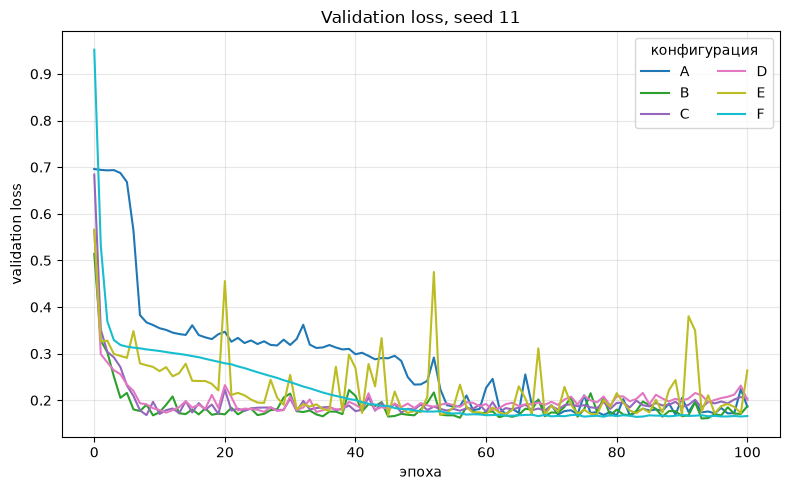

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
for color, code in zip(plt.cm.tab10(np.linspace(0, 1, len(CONFIGS))), CONFIGS):
    hist = HISTORY[(code, 11)]
    ax.plot([r["epoch"] for r in hist], [r["val_loss"] for r in hist],
            color=color, label=code)
ax.set_xlabel("эпоха")
ax.set_ylabel("validation loss")
ax.set_title("Validation loss, seed 11")
ax.legend(title="конфигурация", ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "val_loss_seed11.png", dpi=150)
plt.show()

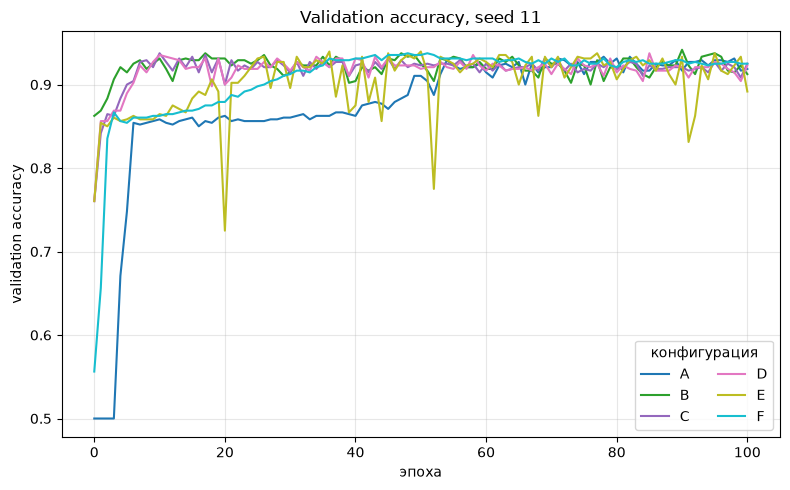

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
for color, code in zip(plt.cm.tab10(np.linspace(0, 1, len(CONFIGS))), CONFIGS):
    hist = HISTORY[(code, 11)]
    ax.plot([r["epoch"] for r in hist], [r["val_accuracy"] for r in hist],
            color=color, label=code)
ax.set_xlabel("эпоха")
ax.set_ylabel("validation accuracy")
ax.set_title("Validation accuracy, seed 11")
ax.legend(title="конфигурация", ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "val_acc_seed11.png", dpi=150)
plt.show()

In [19]:
def first_below(hist, threshold):
    for row in hist:
        if row["val_loss"] < threshold:
            return row["epoch"]
    return None


for code in "ABC":
    h = HISTORY[(code, 11)]
    print(f"{code}: val loss {h[0]['val_loss']:.4f} -> {h[-1]['val_loss']:.4f}, "
          f"val acc {h[0]['val_accuracy']:.3f} -> {h[-1]['val_accuracy']:.3f}")

for code in "CDEF":
    h = HISTORY[(code, 11)]
    print(f"{code}: val loss {h[0]['val_loss']:.4f} -> {h[-1]['val_loss']:.4f}, "
          f"val acc {h[-1]['val_accuracy']:.3f}, "
          f"эпоха с val loss < 0.3: {first_below(h, 0.3)}")

print("seed 29, val loss на 100-й эпохе:")
for code in CONFIGS:
    print(f"{code}: {HISTORY[(code, 29)][-1]['val_loss']:.4f}")

A: val loss 0.6959 -> 0.1863, val acc 0.500 -> 0.919
B: val loss 0.5140 -> 0.1874, val acc 0.863 -> 0.913
C: val loss 0.6841 -> 0.2038, val acc 0.760 -> 0.925
C: val loss 0.6841 -> 0.2038, val acc 0.925, эпоха с val loss < 0.3: 3
D: val loss 0.5655 -> 0.2006, val acc 0.923, эпоха с val loss < 0.3: 1
E: val loss 0.5655 -> 0.2640, val acc 0.892, эпоха с val loss < 0.3: 3
F: val loss 0.9517 -> 0.1662, val acc 0.925, эпоха с val loss < 0.3: 13
seed 29, val loss на 100-й эпохе:
A: 0.1787
B: 0.1714
C: 0.2088
D: 0.2275
E: 0.2942
F: 0.1685


### Что видно

На seed 11 к 100-й эпохе val loss у всех конфигураций лежит в диапазоне
0.1662-0.2640. Лучший результат у F: 0.1662 при 162 параметрах.
Средний val loss по двум seed: F 0.1674, B 0.1794, A 0.1825,
C 0.2063, D 0.2140, E 0.2791.

A стартует хуже всех: на эпохе 0 val loss 0.6959 и accuracy 0.500.
Первые четыре эпохи accuracy держится на 0.500, loss почти не падает
до 6-й эпохи, потом кривая резко идет вниз. У B старт 0.5140 и
accuracy 0.863, у C 0.6841 и 0.760. Sigmoid в A дает плато, Tanh в B
проходит его быстрее. Среди A-C лучший средний результат у B (0.1794),
у A 0.1825, у C 0.2063.

C и D: He в D снижает стартовый loss с 0.6841 до 0.5655 и доводит
val loss ниже 0.3 уже к 1-й эпохе, C тратит на это 3 эпохи. Но к 100-й
эпохе D не выигрывает: на seed 11 у D 0.2006 против 0.2038 у C,
на seed 29 у D 0.2275 против 0.2088 у C. Средние 0.2140 и 0.2063.
Быстрый старт не дал лучшего итога.

E учится медленнее и заканчивает хуже: 0.2640 на 100-й эпохе при
accuracy 0.892, средний val loss 0.2791. Кривая шумная, всплески
около эпох 20, 52 и 91. У E другой и оптимизатор, и learning rate,
поэтому отделить вклад SGD от шага нельзя.

F с одним скрытым слоем дает лучший итог: 0.1662 и accuracy 0.925,
хотя параметров у нее 162 против 5442 у D. Порог val loss 0.3 F проходит
только к 13-й эпохе, то есть сходится медленнее, но обобщает лучше.
Глубина в D не помогла.

На seed 29 порядок почти такой же: F 0.1685 и B 0.1714 лучшие,
E 0.2942 худшая. C и D меняются местами, но разница небольшая.
Двух seed мало для сильных выводов, а разные learning rate в D и E
не дают сравнить оптимизаторы отдельно.

## 4. Диагностика градиентов

Беру первые 128 объектов train в исходном порядке. Для каждого скрытого
слоя считаю норму Фробениуса градиента весов на этом батче. Замеры
делаю по снапшотам эпох 0, 20 и 100 для A, C и D с обоими seed.
Параметры модели не меняю: только forward, backward и обнуление grads.

In [20]:
X_probe = X_train_t[:128].clone()
y_probe = y_train_t[:128].clone()
print("контрольный батч:", tuple(X_probe.shape), tuple(y_probe.shape))

контрольный батч: (128, 2) (128,)


In [21]:
def make_model(config, seed):
    torch.manual_seed(seed)
    return MLP(config["hidden"], WIDTH, config["activation"], config["init"])


def gradient_norms(model, X, y):
    model.eval()
    model.zero_grad(set_to_none=True)
    loss = criterion(model(X), y)
    if not torch.isfinite(loss):
        raise RuntimeError("loss не конечен на контрольном батче")
    loss.backward()
    norms = []
    for i, layer in enumerate(model.layers[:-1], start=1):
        grad = layer.weight.grad
        if grad is None:
            raise RuntimeError(f"нет градиента у слоя {i}")
        if not torch.isfinite(grad).all():
            raise RuntimeError(f"градиент не конечен у слоя {i}")
        norms.append(float(grad.norm(p="fro")))
    model.zero_grad(set_to_none=True)
    return norms, loss.item()

In [22]:
grad_rows = []
zero_norms = 0
for code in ("A", "C", "D"):
    for seed in (11, 29):
        for epoch in (0, 20, 100):
            model = make_model(CONFIGS[code], seed)
            model.load_state_dict(SNAPSHOTS[(code, seed)][epoch])
            norms, probe_loss = gradient_norms(model, X_probe, y_probe)
            zero_norms += sum(1 for n in norms if n == 0.0)
            for layer, norm in enumerate(norms, start=1):
                grad_rows.append({"config": code, "seed": seed, "epoch": epoch,
                                  "layer": layer, "gradient_norm": norm})

print("строк:", len(grad_rows), "нулевых норм:", zero_norms)

with (RES_DIR / "grad_norms.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["config", "seed", "epoch", "layer",
                                           "gradient_norm"])
    writer.writeheader()
    for row in grad_rows:
        writer.writerow({**row, "gradient_norm": f"{row['gradient_norm']:.6e}"})
print("сохранено:", (RES_DIR / "grad_norms.csv").relative_to(ROOT))

строк: 108 нулевых норм: 0
сохранено: results/grad_norms.csv


In [23]:
print(f"{'код':<4}{'seed':<5}{'эпоха':<7}" + "".join(f"{'слой '+str(i):>12}"
      for i in range(1, 7)))
for code in ("A", "C", "D"):
    for seed in (11, 29):
        for epoch in (0, 20, 100):
            values = [row["gradient_norm"] for row in grad_rows
                      if row["config"] == code and row["seed"] == seed
                      and row["epoch"] == epoch]
            print(f"{code:<4}{seed:<5}{epoch:<7}" + "".join(f"{v:>12.4e}"
                  for v in values))

код seed эпоха        слой 1      слой 2      слой 3      слой 4      слой 5      слой 6
A   11   0        1.6302e-04  2.5934e-04  5.0669e-04  2.0395e-03  9.3364e-03  3.9115e-02
A   11   20       1.1430e-02  3.9761e-02  2.6058e-02  2.7513e-02  3.4188e-02  4.6023e-02
A   11   100      7.1271e-02  1.7533e-01  8.5030e-02  5.3751e-02  3.6980e-02  2.8051e-02
A   29   0        1.9849e-04  2.4010e-04  6.9378e-04  1.7063e-03  7.7537e-03  3.2698e-02
A   29   20       9.8135e-03  6.3981e-02  4.5095e-02  3.4793e-02  3.1980e-02  3.7337e-02
A   29   100      6.9238e-02  5.8389e-02  3.2444e-02  2.0100e-02  1.4117e-02  1.2056e-02
C   11   0        4.3164e-02  6.7755e-02  6.8903e-02  6.5507e-02  6.7972e-02  8.0156e-02
C   11   20       5.2433e-01  5.1067e-01  4.1683e-01  3.1196e-01  2.6762e-01  2.3469e-01
C   11   100      1.1243e-01  7.1260e-02  4.9231e-02  3.2042e-02  3.2483e-02  2.0772e-02
C   29   0        9.6353e-02  1.3476e-01  1.1700e-01  7.7222e-02  6.0232e-02  4.4865e-02
C   29   20       1.8

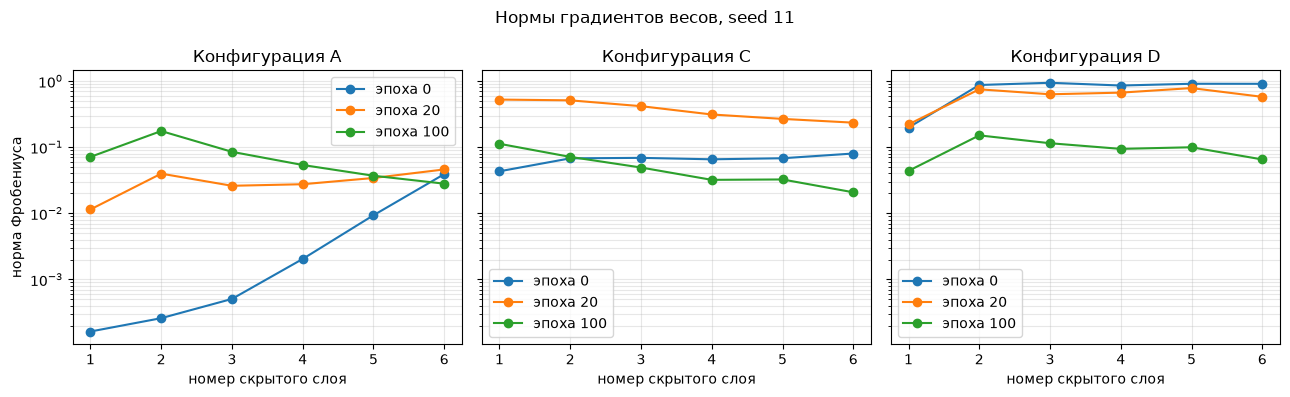

In [24]:
epoch_colors = {0: "#1f77b4", 20: "#ff7f0e", 100: "#2ca02c"}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, code in zip(axes, ("A", "C", "D")):
    for epoch, color in epoch_colors.items():
        values = [row["gradient_norm"] for row in grad_rows
                  if row["config"] == code and row["seed"] == 11
                  and row["epoch"] == epoch]
        ax.plot(range(1, 7), values, marker="o", color=color,
                label=f"эпоха {epoch}")
    ax.set_yscale("log")
    ax.set_title(f"Конфигурация {code}")
    ax.set_xlabel("номер скрытого слоя")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
axes[0].set_ylabel("норма Фробениуса")
fig.suptitle("Нормы градиентов весов, seed 11")
fig.tight_layout()
fig.savefig(FIG_DIR / "grad_norms_seed11.png", dpi=150)
plt.show()

In [25]:
def norm_at(code, seed, epoch, layer):
    for row in grad_rows:
        if (row["config"] == code and row["seed"] == seed
                and row["epoch"] == epoch and row["layer"] == layer):
            return row["gradient_norm"]
    raise KeyError((code, seed, epoch, layer))


for code in ("A", "C", "D"):
    print(code, "seed 11")
    for epoch in (0, 20, 100):
        values = [norm_at(code, 11, epoch, layer) for layer in range(1, 7)]
        print(f"  эпоха {epoch}: слой 1 {values[0]:.3e}, "
              f"слой 6 {values[-1]:.3e}, отношение {values[0] / values[-1]:.3e}")

print("C и D, seed 11, слой 1 и слой 6:")
for epoch in (0, 100):
    print(f"  эпоха {epoch}: C {norm_at('C', 11, epoch, 1):.3e} / "
          f"{norm_at('C', 11, epoch, 6):.3e}; "
          f"D {norm_at('D', 11, epoch, 1):.3e} / "
          f"{norm_at('D', 11, epoch, 6):.3e}")

A seed 11
  эпоха 0: слой 1 1.630e-04, слой 6 3.911e-02, отношение 4.168e-03
  эпоха 20: слой 1 1.143e-02, слой 6 4.602e-02, отношение 2.484e-01
  эпоха 100: слой 1 7.127e-02, слой 6 2.805e-02, отношение 2.541e+00
C seed 11
  эпоха 0: слой 1 4.316e-02, слой 6 8.016e-02, отношение 5.385e-01
  эпоха 20: слой 1 5.243e-01, слой 6 2.347e-01, отношение 2.234e+00
  эпоха 100: слой 1 1.124e-01, слой 6 2.077e-02, отношение 5.413e+00
D seed 11
  эпоха 0: слой 1 1.979e-01, слой 6 9.080e-01, отношение 2.179e-01
  эпоха 20: слой 1 2.210e-01, слой 6 5.768e-01, отношение 3.831e-01
  эпоха 100: слой 1 4.381e-02, слой 6 6.518e-02, отношение 6.721e-01
C и D, seed 11, слой 1 и слой 6:
  эпоха 0: C 4.316e-02 / 8.016e-02; D 1.979e-01 / 9.080e-01
  эпоха 100: C 1.124e-01 / 2.077e-02; D 4.381e-02 / 6.518e-02


### Что видно

На эпохе 0 у A нормы растут от слоя к слою: 1.63e-04 на первом слое
и 3.91e-02 на шестом, разница около 240 раз. Это vanishing gradient.
При обратном проходе через шесть sigmoid производная на каждом слое
не больше 0.25, поэтому сигнал до ранних слоев доходит сильно ослабленным.
К 100-й эпохе картина меняется: 7.13e-02 на первом слое и 2.81e-02
на шестом, ранние слои догоняют поздние.

У C и D на эпохе 0 профиль ровнее: первый и шестой слои отличаются
не больше чем в 5 раз. У ReLU производная не гасит сигнал так, как
sigmoid, поэтому нормы по слоям отличаются в разы, а не в сотни раз.
У D нормы примерно в 5-11 раз больше, чем у C: He normal задает больший
масштаб весов, чем Xavier.

К 100-й эпохе у C 1.12e-01 на первом слое и 2.08e-02 на шестом,
у D 4.38e-02 и 6.52e-02. D сохраняет более ровный профиль, у C градиент
смещается к ранним слоям. При этом средний val loss у C лучше
(0.2063 против 0.2140), хотя стартовые нормы у D были больше.

По одной норме нельзя судить о скорости обучения. Норма зависит
от масштаба активаций слоя и от числа весов: у первого слоя матрица
32x2, это 64 элемента, у скрытых 32x32, это 1024 элемента. При одинаковом
масштабе весов норма 32x32 будет примерно в 4 раза больше уже из-за
размера. Большая норма может означать и полезный шаг, и неустойчивость.
D стартовал быстрее (порог 0.3 на 1-й эпохе), но итог хуже, чем у C.
Validation loss зависит еще и от обобщения, а не только от скорости
убывания train loss.

На seed 29 главное повторяется: у A нормы на эпохе 0 тоже маленькие
в начале (1.98e-04) и большие в конце (3.27e-02), разница около 165 раз.
У C и D такого разрыва нет. Точный порядок слоев зависит от seed:
у C на seed 11 норма растет к шестому слою, на seed 29 падает. У D
на seed 29 стартовые нормы заметно больше, чем на seed 11 (до 3.72),
это говорит о чувствительности He-инициализации к случайности.

Нулевых норм нет (0 из 108), все значения конечные. Проверка на NaN
и Inf встроена в функцию.

## 5. Выбор модели и test

Считаю средний val loss на 100-й эпохе по двум seed. Беру минимум,
при равенстве более раннюю букву. Внутри конфигурации беру запуск
с меньшим val loss, при равенстве seed 11. Test смотрю один раз,
после выбора, и по нему ничего не меняю.

In [26]:
mean_val = {}
for code in CONFIGS:
    mean_val[code] = float(np.mean([HISTORY[(code, seed)][-1]["val_loss"]
                                    for seed in (11, 29)]))

best_config = min(CONFIGS, key=lambda code: (mean_val[code], code))
best_seed = min((11, 29),
                key=lambda seed: (HISTORY[(best_config, seed)][-1]["val_loss"],
                                  seed))

print("средний val loss:")
for code in CONFIGS:
    print(f"{code}: {mean_val[code]:.4f}")
print("выбрана конфигурация:", best_config, "seed:", best_seed)
print("val loss выбранного запуска:",
      f"{HISTORY[(best_config, best_seed)][-1]['val_loss']:.4f}")

средний val loss:
A: 0.1825
B: 0.1794
C: 0.2063
D: 0.2140
E: 0.2791
F: 0.1674
выбрана конфигурация: F seed: 11
val loss выбранного запуска: 0.1662


In [27]:
best_model = RUNS[(best_config, best_seed)]
test_loss, test_acc = compute_metrics(best_model, X_test_t, y_test_t)
last = HISTORY[(best_config, best_seed)][-1]

test_row = {
    "config": best_config,
    "seed": best_seed,
    "train_loss": last["train_loss"],
    "train_accuracy": last["train_accuracy"],
    "val_loss": last["val_loss"],
    "val_accuracy": last["val_accuracy"],
    "test_loss": test_loss,
    "test_accuracy": test_acc,
}
with (RES_DIR / "test_result.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(test_row))
    writer.writeheader()
    writer.writerow({k: (f"{v:.6f}" if isinstance(v, float) else v)
                     for k, v in test_row.items()})

print(f"test loss {test_loss:.4f}, test accuracy {test_acc:.4f}")
print("сохранено:", (RES_DIR / "test_result.csv").relative_to(ROOT))

test loss 0.1302, test accuracy 0.9438
сохранено: results/test_result.csv


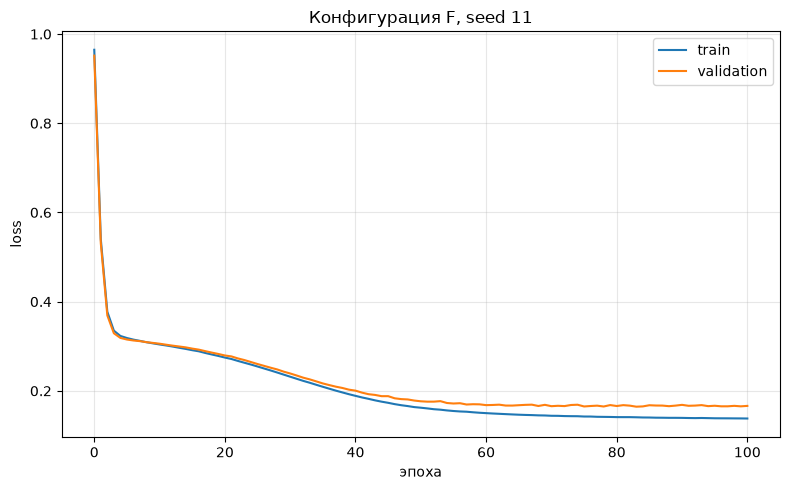

In [28]:
hist = HISTORY[(best_config, best_seed)]
epochs = [row["epoch"] for row in hist]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epochs, [row["train_loss"] for row in hist], label="train")
ax.plot(epochs, [row["val_loss"] for row in hist], label="validation")
ax.set_xlabel("эпоха")
ax.set_ylabel("loss")
ax.set_title(f"Конфигурация {best_config}, seed {best_seed}")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "final_train_val_loss.png", dpi=150)
plt.show()

In [29]:
min_row = min(hist, key=lambda row: row["val_loss"])
print(f"минимум val loss {min_row['val_loss']:.4f} на эпохе {min_row['epoch']}")
print(f"train loss {last['train_loss']:.4f}, val {last['val_loss']:.4f}, "
      f"test {test_loss:.4f}")
print(f"train acc {last['train_accuracy']:.4f}, val {last['val_accuracy']:.4f}, "
      f"test {test_acc:.4f}")
print(f"разрыв train-test по loss: {test_loss - last['train_loss']:.4f}")
print(f"разрыв train-test по accuracy: "
      f"{last['train_accuracy'] - test_acc:.4f}")

минимум val loss 0.1645 на эпохе 83
train loss 0.1380, val 0.1662, test 0.1302
train acc 0.9458, val 0.9250, test 0.9438
разрыв train-test по loss: -0.0078
разрыв train-test по accuracy: 0.0021


### Что видно

Выбор сошелся на F: средний val loss 0.1674, у ближайшего B 0.1794,
у D 0.2140. Внутри F лучше seed 11 (0.1662 против 0.1685).
На 100-й эпохе у выбранного запуска train loss 0.1380, val 0.1662,
test 0.1302; accuracy 0.9458, 0.9250 и 0.9438.

Три вывода:

1. Глубина здесь не помогает. F с одним скрытым слоем и 162 параметрами
дает средний val loss 0.1674, а D с шестью слоями и 5442 параметрами
только 0.2140. Лишние слои усложняют оптимизацию и не дают выигрыша
на этой выборке.

2. У глубокого sigmoid в A есть плато из-за затухания градиента.
На эпохе 0 норма градиента первого слоя 1.63e-04, шестого 3.91e-02,
разница около 240 раз. Первые четыре эпохи accuracy стоит на 0.500,
loss на 0.6959, и только потом кривая падает. У B с Tanh и C с ReLU
такого плато нет.

3. Быстрый старт не равен лучшему итогу. D с He normal сразу имеет
большие нормы градиента и проходит val loss 0.3 на 1-й эпохе, C
на 3-й. Но средний val loss у C лучше: 0.2063 против 0.2140.

Пример вывода, для которого данных мало: по D и E нельзя сказать, что
SGD хуже Adam. У них разные learning rate (0.003 и 0.05), поэтому эффект
оптимизатора смешан с эффектом шага. Похожая история с C и D: на seed 11
D лучше (0.2006 против 0.2038), на seed 29 хуже (0.2275 против 0.2088),
так что двух seed не хватает, чтобы говорить о влиянии инициализации.

По качеству: train loss 0.1380, val 0.1662, test 0.1302, accuracy 0.9458,
0.9250 и 0.9438. Разрыв между train и test маленький и идет в пользу
test, поэтому сильного переобучения нет. Минимум val loss 0.1645
достигается на 83-й эпохе, к 100-й он чуть растет (0.1662), это слабый
признак переобучения. Затруднения оптимизации видны по плато A
и по шумной кривой E со всплесками на эпохах 20, 52 и 91.
